 # **Step 1: Build and Initialize the CNN Model**
 Creates a simple CNN with two convolutional layers.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Build a CNN using stride and padding
model = tf.keras.Sequential([

    # Input layer
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # First Conv2D layer
    tf.keras.layers.Conv2D(
        filters=8,
        kernel_size=(3, 3),
        strides=(1, 1),
        padding='same',
        activation='relu',
        name='conv_layer_1'
    ),

    # Max Pooling layer
    tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2),
        strides=(2, 2),
        padding='same',
        name='max_pooling'
    ),

    # Second Conv2D layer
    tf.keras.layers.Conv2D(
        filters=16,
        kernel_size=(3, 3),
        strides=(2, 2),
        padding='same',
        activation='relu',
        name='conv_layer_2'
    )
])

# Display model structure
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_layer_1 (Conv2D)           │ (None, 28, 28, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling (MaxPooling2D)      │ (None, 14, 14, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_layer_2 (Conv2D)           │ (None, 7, 7, 16)       │         1,168 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,248 (4.88 KB)

 Trainable params: 1,248 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

# **Step 2: Create and Display the Input Image**
Generates a white circle on a black background as the test input.

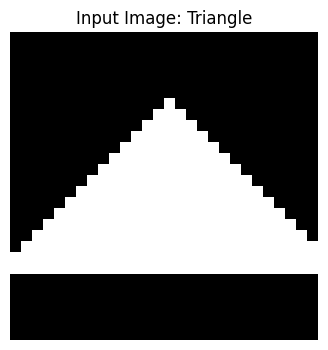

In [3]:
# Step 2: Create and Display a Triangle Image

img = np.zeros((28, 28, 1))

# Create a white triangle
for i in range(6, 22):
    for j in range(28):

        # Triangle condition
        if 14 - (i - 6) <= j <= 14 + (i - 6):
            img[i, j] = 1.0

# Add batch dimension
img = img.reshape(1, 28, 28, 1).astype(np.float32)

# Display the input image
plt.figure(figsize=(4, 4))

plt.imshow(img[0, :, :, 0], cmap='gray')
plt.title("Input Image: Triangle")
plt.axis('off')

plt.show()

# **Step 3: Visualize Feature Maps from the First Convolutional Layer:**
Displays the 8 feature maps produced by the first Conv2D layer.

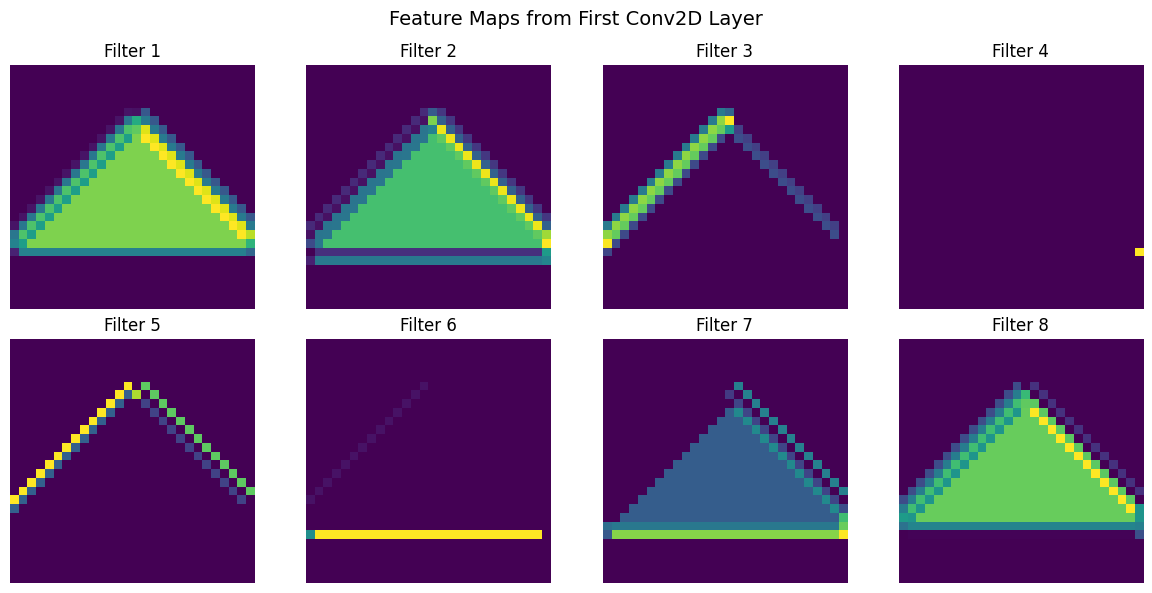

Feature map shape: (1, 28, 28, 8)


In [4]:
# Step 3: Get feature maps from the first Conv2D layer

# Select the first Conv2D layer
conv_layer = model.layers[0]

# Create a model that outputs the activation of the first Conv2D layer
activation_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=conv_layer.output
)

# Extract feature maps
feature_maps = activation_model.predict(img, verbose=0)

# Number of feature maps
num_features = feature_maps.shape[-1]

# Create plots for 8 feature maps
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten()

# Display feature maps
for i in range(num_features):
    axes[i].imshow(feature_maps[0, :, :, i], cmap='viridis')
    axes[i].set_title(f"Filter {i+1}")
    axes[i].axis('off')

plt.suptitle("Feature Maps from First Conv2D Layer", fontsize=14)
plt.tight_layout()
plt.show()

# Print feature map dimensions
print(f"Feature map shape: {feature_maps.shape}")

# **Step 4: Visualize Feature Maps from the Second Convolutional Layer**
Displays the 16 feature maps produced by the second Conv2D layer.

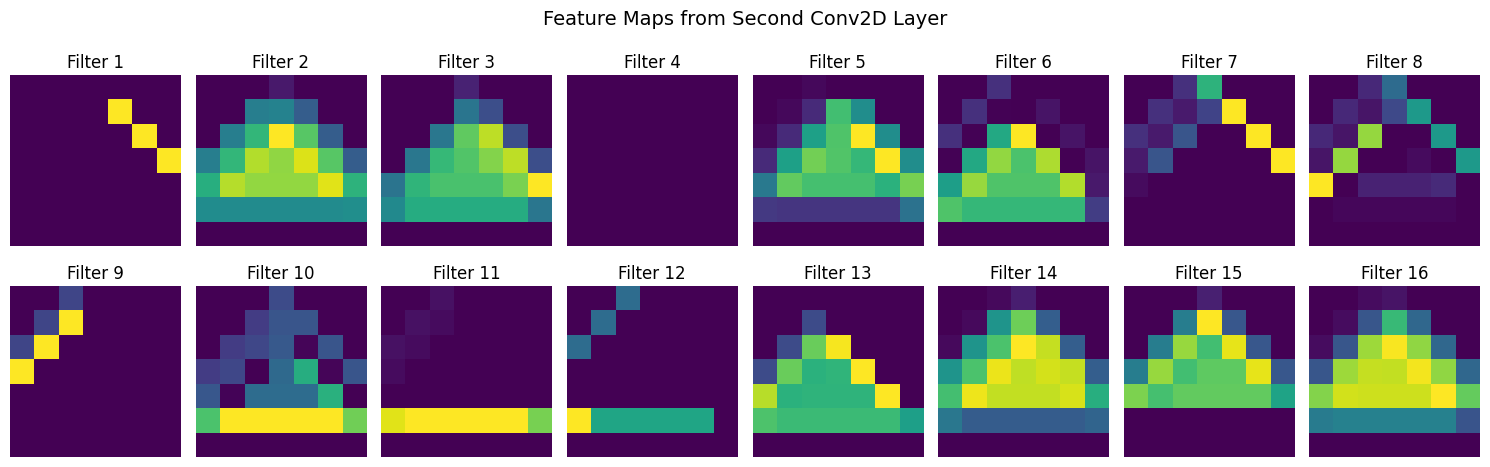

Feature map shape: (1, 7, 7, 16)


In [5]:
# Step 4: Get feature maps from the second Conv2D layer

# Select the second Conv2D layer
conv_layer = model.layers[2]

# Create activation model
activation_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=conv_layer.output
)

# Generate feature maps
feature_maps = activation_model.predict(img, verbose=0)

# Number of feature maps
num_features = feature_maps.shape[-1]

# Grid settings
cols = 8
rows = (num_features + cols - 1) // cols

# Create plots
fig, axes = plt.subplots(rows, cols, figsize=(15, 5))
axes = axes.flatten()

# Display all 16 feature maps
for i in range(num_features):
    axes[i].imshow(feature_maps[0, :, :, i], cmap='viridis')
    axes[i].set_title(f"Filter {i + 1}")
    axes[i].axis('off')

# Hide unused axes
for i in range(num_features, len(axes)):
    axes[i].axis('off')

plt.suptitle("Feature Maps from Second Conv2D Layer", fontsize=14)
plt.tight_layout()
plt.show()

# Print feature map shape
print("Feature map shape:", feature_maps.shape)

# **Step 5: Visualize Feature Maps from All CNN Layers**
Displays and compares the feature maps generated at each layer of the CNN.


Layer: conv_layer_1
Output shape: (1, 28, 28, 8)


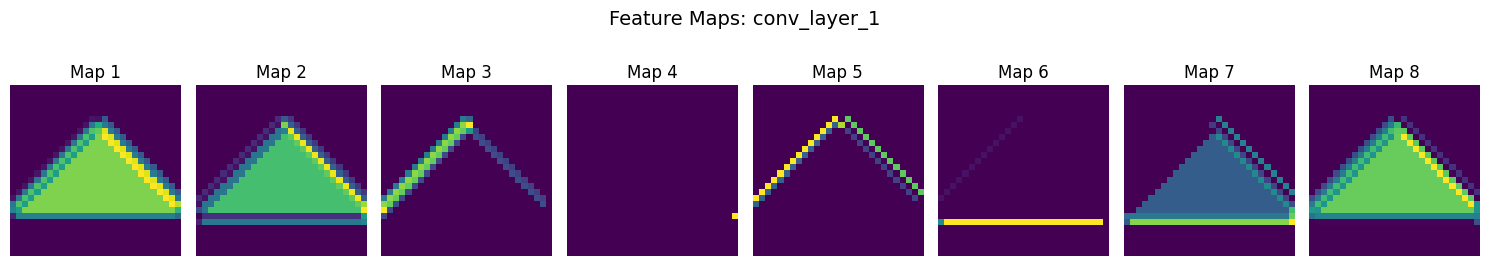


Layer: max_pooling
Output shape: (1, 14, 14, 8)


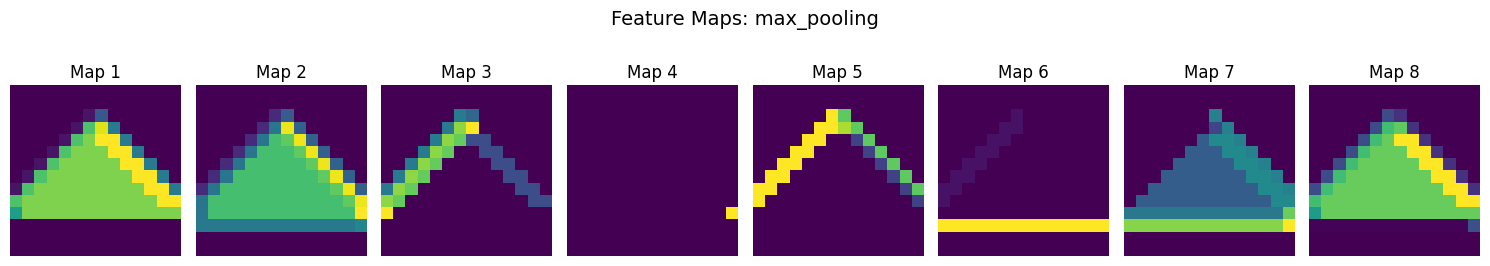


Layer: conv_layer_2
Output shape: (1, 7, 7, 16)


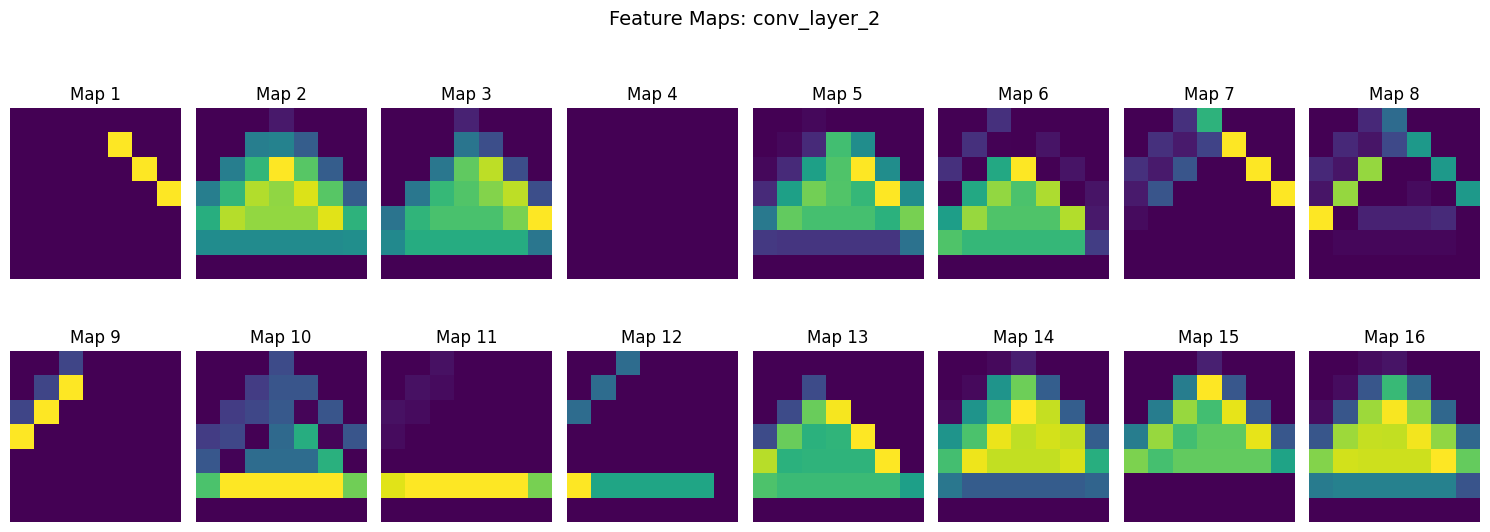

In [6]:
# Step 5: Visualize feature maps from all CNN layers

# Get outputs from all layers
layer_outputs = [layer.output for layer in model.layers]

# Create a model that returns all layer outputs
activation_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=layer_outputs
)

# Generate activations for the input image
activations = activation_model.predict(img, verbose=0)

# Visualize feature maps from each layer
for layer, activation in zip(model.layers, activations):

    print(f"\nLayer: {layer.name}")
    print(f"Output shape: {activation.shape}")

    # Number of feature maps
    num_features = activation.shape[-1]

    # Display maximum 16 feature maps
    display_features = min(num_features, 16)

    cols = 8
    rows = (display_features + cols - 1) // cols

    # Create subplot
    fig, axes = plt.subplots(
        rows, cols,
        figsize=(15, 3 * rows)
    )

    # Convert axes into a flat array
    axes = np.array(axes).flatten()

    # Display feature maps
    for i in range(display_features):
        axes[i].imshow(
            activation[0, :, :, i],
            cmap='viridis'
        )
        axes[i].set_title(f"Map {i + 1}")
        axes[i].axis('off')

    # Hide unused axes
    for i in range(display_features, len(axes)):
        axes[i].axis('off')

    plt.suptitle(
        f"Feature Maps: {layer.name}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()